# Environment Setup

In [1]:
import re
import math
import unicodedata
from pathlib import Path
from itertools import chain

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


# Dataset Exploration

In [2]:
files = sorted(
    p for p in Path("/kaggle/input").rglob("*.txt")
    if "children-stories-text-corpus" in str(p)
)

assert files, "Attach the Children Stories Text Corpus dataset."

file_path = max(files, key=lambda p: p.stat().st_size)
raw_text = file_path.read_text(encoding="utf-8", errors="replace")

print("File:", file_path.name)
print(f"Characters: {len(raw_text):,}")
print(f"Words: {len(raw_text.split()):,}")
print(f"\nSample Text:\n{raw_text[:1500]}")

File: cleaned_merged_fairy_tales_without_eos.txt
Characters: 20,455,694
Words: 3,792,498

Sample Text:
The Happy Prince.
HIGH above the city, on a tall column, stood the statue of the Happy Prince.  He was gilded all over with thin leaves of fine gold, for eyes he had two bright sapphires, and a large red ruby glowed on his sword-hilt.
He was very much admired indeed.  “He is as beautiful as a weathercock,” remarked one of the Town Councillors who wished to gain a reputation for having artistic tastes; “only not quite so useful,” he added, fearing lest people should think him unpractical, which he really was not.
“Why can’t you be like the Happy Prince?” asked a sensible mother of her little boy who was crying for the moon.  “The Happy Prince never dreams of crying for anything.”
“I am glad there is some one in the world who is quite happy,” muttered a disappointed man as he gazed at the wonderful statue.
“He looks just like an angel,” said the Charity Children as they came out of the 

# Text Preprocessing

In [3]:
def preprocess(text):
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\ufeff", "")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

text = preprocess(raw_text)

print(f"Original characters: {len(raw_text):,}")
print(f"Cleaned characters: {len(text):,}")
print(text[:1000])

Original characters: 20,455,694
Cleaned characters: 20,404,149
The Happy Prince.
HIGH above the city, on a tall column, stood the statue of the Happy Prince. He was gilded all over with thin leaves of fine gold, for eyes he had two bright sapphires, and a large red ruby glowed on his sword-hilt.
He was very much admired indeed. “He is as beautiful as a weathercock,” remarked one of the Town Councillors who wished to gain a reputation for having artistic tastes; “only not quite so useful,” he added, fearing lest people should think him unpractical, which he really was not.
“Why can’t you be like the Happy Prince?” asked a sensible mother of her little boy who was crying for the moon. “The Happy Prince never dreams of crying for anything.”
“I am glad there is some one in the world who is quite happy,” muttered a disappointed man as he gazed at the wonderful statue.
“He looks just like an angel,” said the Charity Children as they came out of the cathedral in their bright scarlet cloaks an

# Train, Validation & Test Split

In [4]:
n = len(text)

train_end = text.rfind(" ", 0, int(n * 0.90))
val_end = text.rfind(" ", 0, int(n * 0.95))

train_text = text[:train_end]
val_text = text[train_end:val_end]
test_text = text[val_end:]

print(f"Training:   {len(train_text):,} characters")
print(f"Validation: {len(val_text):,} characters")
print(f"Testing:    {len(test_text):,} characters")

Training:   18,363,733 characters
Validation: 1,020,204 characters
Testing:    1,020,212 characters


# BPE Tokenization

In [5]:
tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=4096,
    special_tokens=["<unk>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
)

tokenizer.train_from_iterator(
    train_text.splitlines(keepends=True), trainer=trainer
)

VOCAB_SIZE = tokenizer.get_vocab_size()

def encode(text):
    ids = chain.from_iterable(
        tokenizer.encode(line).ids
        for line in text.splitlines(keepends=True)
    )
    return torch.tensor(list(ids), dtype=torch.long)

train_ids = encode(train_text)
val_ids = encode(val_text)
test_ids = encode(test_text)

print("Vocabulary Size:", VOCAB_SIZE)
print("Training Tokens:", len(train_ids))
print("Sample:", tokenizer.encode("Once upon a time").tokens)




Vocabulary Size: 4096
Training Tokens: 5082418
Sample: ['Once', 'Ġupon', 'Ġa', 'Ġtime']


# Custom Dataset & DataLoader

In [6]:
BLOCK_SIZE = 256
BATCH_SIZE = 16

class StoryDataset(Dataset):
    def __init__(self, tokens):
        self.tokens = tokens

    def __len__(self):
        return (len(self.tokens) - 1) // BLOCK_SIZE

    def __getitem__(self, idx):
        start = idx * BLOCK_SIZE
        chunk = self.tokens[start:start + BLOCK_SIZE + 1]
        return chunk[:-1], chunk[1:]

train_dataset = StoryDataset(train_ids)
val_dataset = StoryDataset(val_ids)
test_dataset = StoryDataset(test_ids)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, pin_memory=torch.cuda.is_available())

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

x, y = next(iter(train_loader))
print("Input Shape:", x.shape)
print("Target Shape:", y.shape)

Input Shape: torch.Size([16, 256])
Target Shape: torch.Size([16, 256])


# GPT Architecture Implementation

## Causal Self-Attention

In [7]:
class CausalSelfAttention(nn.Module):
    def __init__(self, dim, heads, dropout):
        super().__init__()
        self.heads = heads
        self.head_dim = dim // heads
        self.dropout = dropout

        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)

    def forward(self, x):
        B, T, C = x.shape

        q, k, v = self.qkv(x).chunk(3, dim=-1)

        q, k, v = [
            t.reshape(B, T, self.heads, self.head_dim).transpose(1, 2)
            for t in (q, k, v)
        ]

        out = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=True,
            dropout_p=self.dropout if self.training else 0.0
        )

        out = out.transpose(1, 2).reshape(B, T, C)
        return self.proj(out)

## Transformer Decoder Block

In [8]:
class TransformerBlock(nn.Module):
    def __init__(self, dim, heads, dropout):
        super().__init__()

        self.ln1 = nn.LayerNorm(dim)
        self.ln2 = nn.LayerNorm(dim)

        self.attn = CausalSelfAttention(dim, heads, dropout)

        self.ffn = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.GELU(),
            nn.Linear(4 * dim, dim),
            nn.Dropout(dropout)
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = x + self.dropout(self.attn(self.ln1(x)))
        x = x + self.ffn(self.ln2(x))
        return x

## Complete GPT Model

In [9]:
class GPT(nn.Module):
    def __init__(self, vocab_size, block_size, dim, heads, layers, dropout):
        super().__init__()

        self.token_emb = nn.Embedding(vocab_size, dim)
        self.pos_emb = nn.Embedding(block_size, dim)
        self.dropout = nn.Dropout(dropout)

        self.blocks = nn.Sequential(*[
            TransformerBlock(dim, heads, dropout)
            for _ in range(layers)
        ])

        self.norm = nn.LayerNorm(dim)
        self.lm_head = nn.Linear(dim, vocab_size, bias=False)

        # Weight tying
        self.lm_head.weight = self.token_emb.weight

        for p in self.parameters():
            if p.dim() > 1:
                nn.init.normal_(p, mean=0.0, std=0.02)

    def forward(self, x):
        positions = torch.arange(x.size(1), device=x.device)

        x = self.token_emb(x) + self.pos_emb(positions)
        x = self.dropout(x)
        x = self.blocks(x)

        return self.lm_head(self.norm(x))

## Model Initialization

In [10]:
config = {
    "vocab_size": VOCAB_SIZE,
    "block_size": BLOCK_SIZE,
    "dim": 256,
    "heads": 4,
    "layers": 4,
    "dropout": 0.1
}

model = GPT(**config).to(device)

params = sum(p.numel() for p in model.parameters())
print(f"Total Parameters: {params:,}")

with torch.no_grad():
    logits = model(x.to(device))

print("Output Shape:", logits.shape)

Total Parameters: 4,273,664
Output Shape: torch.Size([16, 256, 4096])


# Model Training & Validation

## Training Setup & Epoch Function

In [11]:
EPOCHS = 15
LEARNING_RATE = 3e-4

optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def run_epoch(loader, training=False):
    model.train(training)
    total_loss, total_tokens = 0, 0

    for x, y in tqdm(loader, leave=False):
        x, y = x.to(device), y.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=device.type,
                                dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(
                    logits.reshape(-1, VOCAB_SIZE), y.reshape(-1)
                )

        if training:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()

        total_loss += loss.item() * y.numel()
        total_tokens += y.numel()

    return total_loss / total_tokens

## Training Loop

In [12]:
history = {"train_loss": [], "val_loss": []}
best_loss = float("inf")

for epoch in range(EPOCHS):
    train_loss = run_epoch(train_loader, training=True)
    val_loss = run_epoch(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_loss:
        best_loss = val_loss
        torch.save({
            "config": config,
            "model_state_dict": model.state_dict()
        }, "storyforge_gpt.pt")

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"Val PPL: {math.exp(val_loss):.2f}")

  0%|          | 0/1241 [00:00<?, ?it/s]

  0%|          | 0/70 [00:00<?, ?it/s]

Epoch 1/15 | Train Loss: 5.2308 | Val Loss: 4.7253 | Val PPL: 112.76


  0%|          | 0/1241 [00:00<?, ?it/s]

  0%|          | 0/70 [00:00<?, ?it/s]

Epoch 2/15 | Train Loss: 4.4837 | Val Loss: 4.3871 | Val PPL: 80.41


... (35 outputs left out)

Epoch 14/15 | Train Loss: 3.6358 | Val Loss: 3.7982 | Val PPL: 44.62


  0%|          | 0/1241 [00:00<?, ?it/s]

  0%|          | 0/70 [00:00<?, ?it/s]

Epoch 15/15 | Train Loss: 3.6163 | Val Loss: 3.7766 | Val PPL: 43.67


# Performance Evaluation

## Training & Validation Loss Visualization

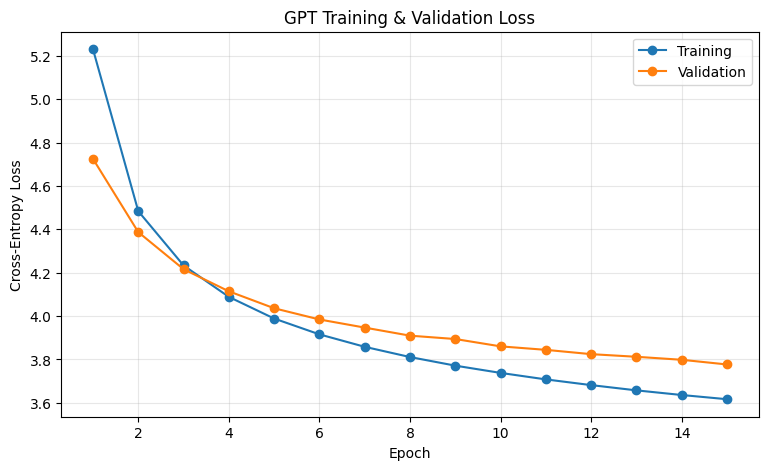

In [13]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("GPT Training & Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Test Loss & Perplexity

In [14]:
checkpoint = torch.load(
    "storyforge_gpt.pt", map_location=device, weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])

test_loss = run_epoch(test_loader)
perplexity = math.exp(test_loss)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Perplexity: {perplexity:.2f}")

  0%|          | 0/74 [00:00<?, ?it/s]

Test Loss: 4.1137
Test Perplexity: 61.17


# Autoregressive Story Generation

## Generation Function

In [15]:
@torch.inference_mode()
def generate(prompt, max_new_tokens=200, temperature=0.8, top_k=40):
    model.eval()

    ids = tokenizer.encode(prompt).ids
    x = torch.tensor([ids], dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        context = x[:, -BLOCK_SIZE:]
        logits = model(context)[:, -1, :] / temperature

        values, indices = torch.topk(logits, min(top_k, VOCAB_SIZE))
        probs = F.softmax(values, dim=-1)

        next_token = indices.gather(1, torch.multinomial(probs, 1))
        x = torch.cat((x, next_token), dim=1)

    return tokenizer.decode(x[0].tolist())

## Test Story Generation

In [16]:
prompts = [
    "Once upon a time",
    "There lived a little princess",
    "Deep inside the magical forest",
    "One day, a young boy discovered"
]

for prompt in prompts:
    print(f"\nPROMPT: {prompt}")
    print(generate(prompt, max_new_tokens=200))
    print("-" * 80)


PROMPT: Once upon a time
Once upon a time that a great many years ago; the Prince was not much astonished, but he began to be looking at me, and in the same voice the voice of the Prince came with great beauty that it was only three years old, who had been known by his death, and had been found the greatest desire for his own.
After some time, he had found a great deal of courage and was not prepared for his life.
But he had a good opportunity of getting out of the kingdom that grew up to it, and he had to look into a rupees, and had not been able to get rid of him.
The Prince could not get him, however, so that the whole of it was not long since he was so much surprised to find it very hard to see that he was to be a man. The poor old man saw himself, and said, "I want to buy them a golden spoon and a pear."
"What do you think of that?" said
--------------------------------------------------------------------------------

PROMPT: There lived a little princess
There lived a little pri

# Save Model & Tokenizer

In [17]:
tokenizer.save("storyforge_tokenizer.json")

print("Model saved: storyforge_gpt.pt")
print("Tokenizer saved: storyforge_tokenizer.json")

Model saved: storyforge_gpt.pt
Tokenizer saved: storyforge_tokenizer.json
